In [1]:

import os
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = r"D:\ML_project\dataset\dataset_small"

data = []

for gesture in sorted(os.listdir(dataset_path)):
    gesture_path = os.path.join(dataset_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    images = [
        f for f in os.listdir(gesture_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for filename in images:
        data.append({
            "filename": filename,
            "gesture": gesture,
            "path": os.path.join(gesture_path, filename)
        })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nImages per gesture:")
print(df["gesture"].value_counts().sort_index())


Total images: 20000

Images per gesture:
gesture
c             2000
down          2000
fist          2000
fist_moved    2000
index         2000
l             2000
ok            2000
palm          2000
palm_moved    2000
thumb         2000
Name: count, dtype: int64


Step 3: Data Visualization — Gesture Class Distribution

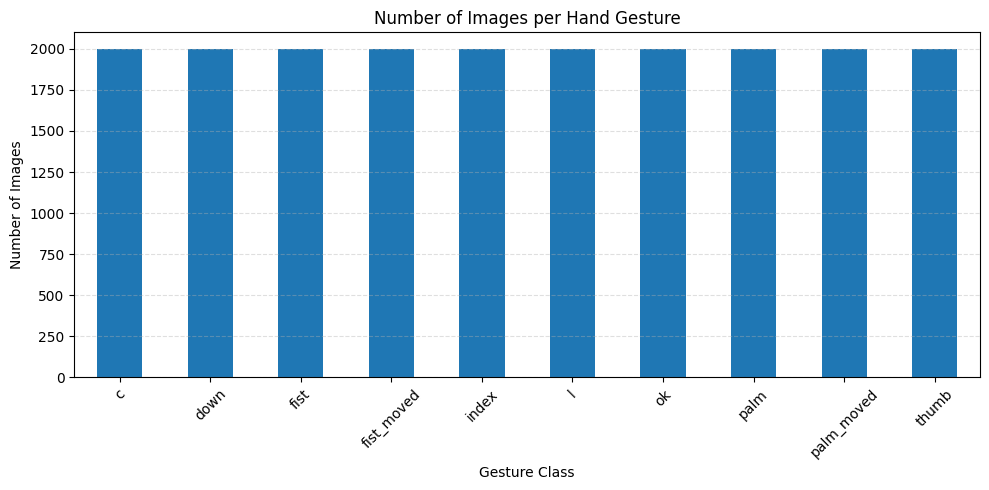

In [4]:

# Count images in each gesture class
class_counts = df["gesture"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("Number of Images per Hand Gesture")
plt.xlabel("Gesture Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


Step 4: Sample Images Visualization

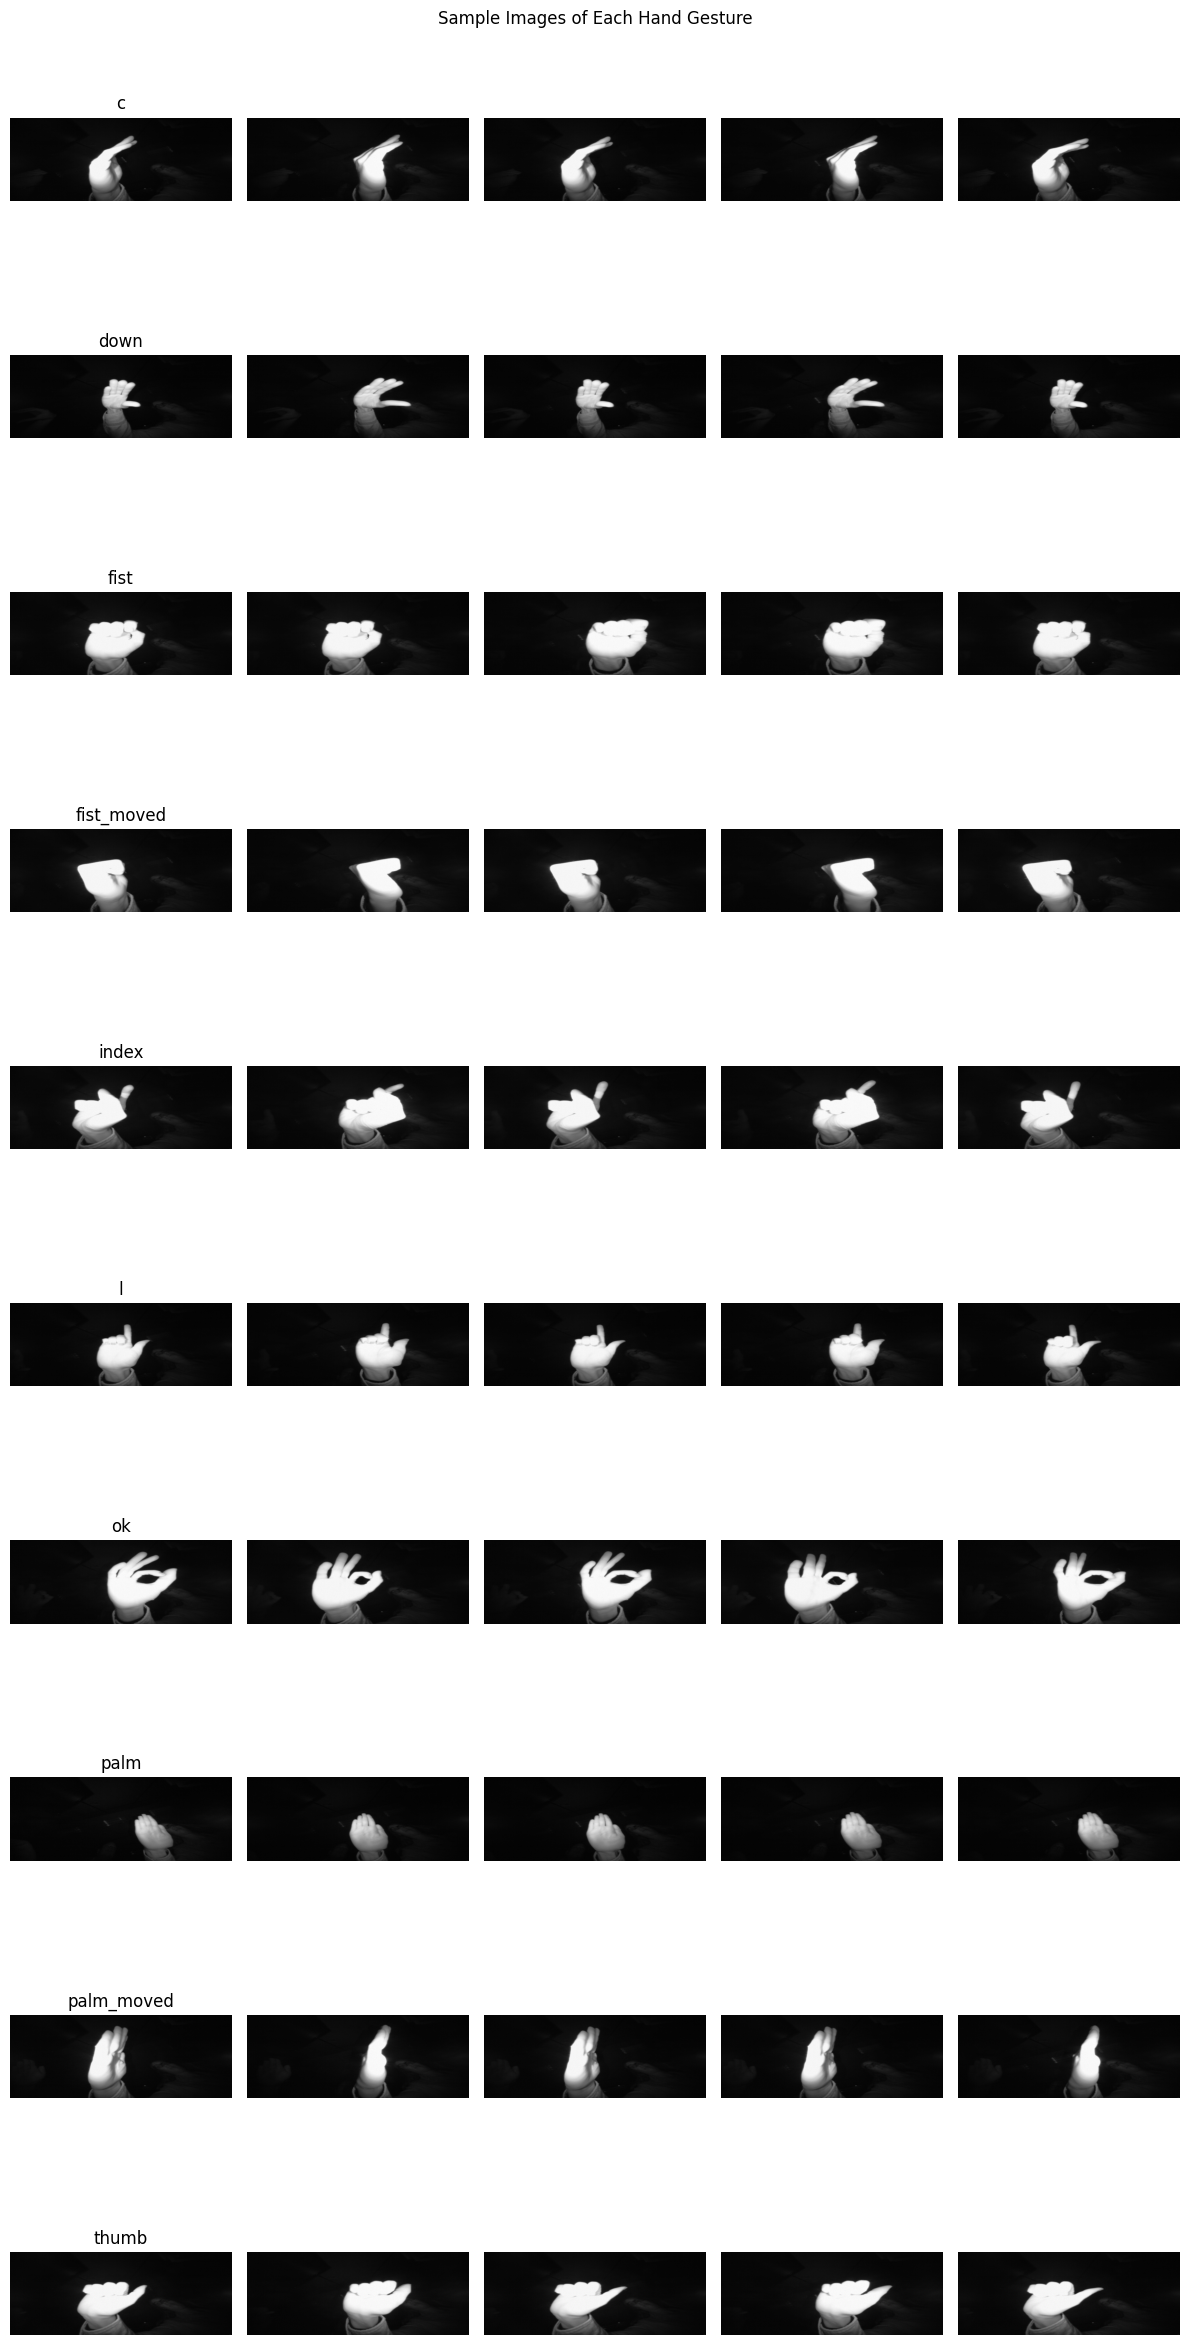

In [5]:

import matplotlib.pyplot as plt
from PIL import Image

# Get all gesture classes
gestures = sorted(df["gesture"].unique())

# Show 5 images from each gesture
fig, axes = plt.subplots(
    len(gestures), 5,
    figsize=(12, 2.5 * len(gestures))
)

for row, gesture in enumerate(gestures):

    samples = df[df["gesture"] == gesture].head(5)

    for col in range(5):
        ax = axes[row, col]

        if col < len(samples):
            image_path = samples.iloc[col]["path"]

            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(gesture if col == 0 else "")

        ax.axis("off")

plt.suptitle("Sample Images of Each Hand Gesture")
plt.tight_layout()
plt.show()


Step 5: Data Cleaning

In [6]:

from PIL import Image
import os

corrupt_images = []
total_checked = 0

for image_path in df["path"]:
    total_checked += 1

    try:
        with Image.open(image_path) as img:
            img.verify()

    except (OSError, ValueError):
        corrupt_images.append(image_path)

print("Total images checked:", total_checked)
print("Corrupt images found:", len(corrupt_images))

if corrupt_images:
    print("\nCorrupt image paths:")
    for path in corrupt_images:
        print(path)
else:
    print("All images passed the basic integrity check.")


Total images checked: 20000
Corrupt images found: 0
All images passed the basic integrity check.


Step 6: Duplicate Images Check

In [7]:

import hashlib
from collections import defaultdict

# Store image hashes
image_hashes = defaultdict(list)

for image_path in df["path"]:
    try:
        with open(image_path, "rb") as file:
            image_bytes = file.read()

        # Generate unique hash for image content
        image_hash = hashlib.md5(image_bytes).hexdigest()

        image_hashes[image_hash].append(image_path)

    except OSError:
        print("Could not read:", image_path)

# Find exact duplicates
duplicate_groups = [
    paths for paths in image_hashes.values()
    if len(paths) > 1
]

duplicate_count = sum(
    len(paths) - 1 for paths in duplicate_groups
)

print("Total images:", len(df))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate images:", duplicate_count)

for group in duplicate_groups[:5]:
    print("\nDuplicate files:")
    for path in group:
        print(path)


Total images: 20000
Duplicate groups: 388
Extra duplicate images: 392

Duplicate files:
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0007.png
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0008.png

Duplicate files:
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0009.png
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0010.png

Duplicate files:
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0015.png
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0016.png

Duplicate files:
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0017.png
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0018.png

Duplicate files:
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0033.png
D:\ML_project\dataset\dataset_small\c\00_09_c_frame_00_09_0034.png


Duplicate classes inspect karo

In [8]:

from collections import defaultdict
import hashlib
import os

image_hashes = defaultdict(list)

for _, row in df.iterrows():
    image_path = row["path"]

    try:
        with open(image_path, "rb") as file:
            image_hash = hashlib.md5(file.read()).hexdigest()

        image_hashes[image_hash].append({
            "path": image_path,
            "gesture": row["gesture"]
        })

    except OSError:
        pass

duplicate_groups = [
    items for items in image_hashes.values()
    if len(items) > 1
]

cross_class_groups = []

for group in duplicate_groups:
    classes = set(item["gesture"] for item in group)

    if len(classes) > 1:
        cross_class_groups.append(group)

print("Total duplicate groups:", len(duplicate_groups))
print("Duplicates across different classes:", len(cross_class_groups))

for group in cross_class_groups[:10]:
    print("\nDuplicate group:")
    for item in group:
        print("Class:", item["gesture"], "| File:", os.path.basename(item["path"]))


Total duplicate groups: 388
Duplicates across different classes: 0


clean dataset

In [11]:

import os
import shutil
import hashlib
from collections import defaultdict

source_path = r"D:\ML_project\dataset\dataset_small"
clean_path = r"D:\ML_project\dataset\dataset_clean"

# Avoid overwriting an existing clean dataset
if os.path.exists(clean_path):
    print("dataset_clean already exists.")
    print("Please rename or remove it before running this cell again.")
else:
    os.makedirs(clean_path)

    for gesture in sorted(os.listdir(source_path)):
        gesture_path = os.path.join(source_path, gesture)

        if not os.path.isdir(gesture_path):
            continue

        destination_gesture = os.path.join(clean_path, gesture)
        os.makedirs(destination_gesture)

        seen_hashes = set()
        removed_count = 0

        for filename in sorted(os.listdir(gesture_path)):
            if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
                continue

            source_file = os.path.join(gesture_path, filename)

            try:
                with open(source_file, "rb") as file:
                    image_hash = hashlib.md5(file.read()).hexdigest()
            except OSError:
                continue

            if image_hash in seen_hashes:
                removed_count += 1
                continue

            seen_hashes.add(image_hash)

            shutil.copy2(
                source_file,
                os.path.join(destination_gesture, filename)
            )

        print(gesture, "- extra duplicates skipped:", removed_count)

    print("\nClean dataset created:", clean_path)


c - extra duplicates skipped: 42
down - extra duplicates skipped: 0
fist - extra duplicates skipped: 87
fist_moved - extra duplicates skipped: 0
index - extra duplicates skipped: 0
l - extra duplicates skipped: 14
ok - extra duplicates skipped: 0
palm - extra duplicates skipped: 42
palm_moved - extra duplicates skipped: 186
thumb - extra duplicates skipped: 21

Clean dataset created: D:\ML_project\dataset\dataset_clean


Clean dataset verify karo

In [12]:

clean_path = r"D:\ML_project\dataset\dataset_clean"

total_images = 0

for gesture in sorted(os.listdir(clean_path)):
    gesture_path = os.path.join(clean_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    count = sum(
        1 for f in os.listdir(gesture_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    )

    total_images += count
    print(gesture, ":", count)

print("\nTotal clean images:", total_images)


c : 1958
down : 2000
fist : 1913
fist_moved : 2000
index : 2000
l : 1986
ok : 2000
palm : 1958
palm_moved : 1814
thumb : 1979

Total clean images: 19608


Image Dimensions aur Color Mode Analysis

In [13]:

import os
import pandas as pd
from PIL import Image

clean_path = r"D:\ML_project\dataset\dataset_clean"

image_info = []

for gesture in sorted(os.listdir(clean_path)):
    gesture_path = os.path.join(clean_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    for filename in os.listdir(gesture_path):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(gesture_path, filename)

        try:
            with Image.open(image_path) as img:
                image_info.append({
                    "filename": filename,
                    "gesture": gesture,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode
                })

        except (OSError, ValueError):
            print("Cannot open:", image_path)

dimensions_df = pd.DataFrame(image_info)

print("Total readable images:", len(dimensions_df))

print("\nImage dimensions:")
print(
    dimensions_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print("\nColor modes:")
print(dimensions_df["mode"].value_counts())


Total readable images: 19608

Image dimensions:
width  height
640    240       19608
dtype: int64

Color modes:
mode
L    19608
Name: count, dtype: int64


Images ko preprocess karna 
Har image ke pixels 640 × 240 se reduce hokar 64 × 64 honge

In [14]:
import os
import numpy as np
from PIL import Image

clean_path = r"D:\ML_project\dataset\dataset_clean"

X = []
y = []

image_size = (64, 64)

for gesture in sorted(os.listdir(clean_path)):
    gesture_path = os.path.join(clean_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    for filename in sorted(os.listdir(gesture_path)):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(gesture_path, filename)

        with Image.open(image_path) as img:
            img = img.convert("L")
            img = img.resize(image_size)

            # Convert pixels to numbers between 0 and 1
            image_array = np.array(img, dtype=np.float32) / 255.0

            X.append(image_array.flatten())
            y.append(gesture)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Feature matrix shape: (19608, 4096)
Labels shape: (19608,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


train test split

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (15686, 4096)
Testing features: (3922, 4096)
Training labels: (15686,)
Testing labels: (3922,)


Pehla ML model train karna
KNN model

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", round(accuracy * 100, 2), "%")

KNN Accuracy: 99.87 %


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_knn) * 100, 2), "%")

print("Precision:", round(
    precision_score(y_test, y_pred_knn, average="macro", zero_division=0) * 100, 2), "%")

print("Recall:", round(
    recall_score(y_test, y_pred_knn, average="macro", zero_division=0) * 100, 2), "%")

print("F1-score:", round(
    f1_score(y_test, y_pred_knn, average="macro", zero_division=0) * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn, zero_division=0))

Accuracy: 99.87 %
Precision: 99.87 %
Recall: 99.87 %
F1-score: 99.87 %

Classification Report:

              precision    recall  f1-score   support

           c       1.00      1.00      1.00       392
        down       1.00      1.00      1.00       400
        fist       1.00      0.99      1.00       382
  fist_moved       1.00      1.00      1.00       400
       index       1.00      1.00      1.00       400
           l       1.00      1.00      1.00       397
          ok       1.00      1.00      1.00       400
        palm       1.00      0.99      1.00       392
  palm_moved       1.00      1.00      1.00       363
       thumb       1.00      1.00      1.00       396

    accuracy                           1.00      3922
   macro avg       1.00      1.00      1.00      3922
weighted avg       1.00      1.00      1.00      3922



In [19]:
import os

clean_path = r"D:\ML_project\dataset\dataset_clean"

for gesture in sorted(os.listdir(clean_path)):
    gesture_path = os.path.join(clean_path, gesture)

    if os.path.isdir(gesture_path):
        images = [
            f for f in os.listdir(gesture_path)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        if images:
            print(gesture, ":", images[0])

c : 00_09_c_frame_00_09_0001.png
down : 00_10_down_frame_00_10_0001.png
fist : 00_03_fist_frame_00_03_0001.png
fist_moved : 00_04_fist_moved_frame_00_04_0001.png
index : 00_06_index_frame_00_06_0001.png
l : 00_02_l_frame_00_02_0001.png
ok : 00_07_ok_frame_00_07_0001.png
palm : 00_01_palm_frame_00_01_0001.png
palm_moved : 00_08_palm_moved_frame_00_08_0001.png
thumb : 00_05_thumb_frame_00_05_0001.png


In [20]:
import os

clean_path = r"D:\ML_project\dataset\dataset_clean"

subjects = set()

for gesture in os.listdir(clean_path):
    gesture_path = os.path.join(clean_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    for filename in os.listdir(gesture_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            subject_id = filename.split("_")[0]
            subjects.add(subject_id)

print("Number of subjects:", len(subjects))
print("Subject IDs:", sorted(subjects))

Number of subjects: 10
Subject IDs: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09']


In [21]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

clean_path = r"D:\ML_project\dataset\dataset_clean"

X = []
y = []
subject_ids = []

image_size = (64, 64)

for gesture in sorted(os.listdir(clean_path)):
    gesture_path = os.path.join(clean_path, gesture)

    if not os.path.isdir(gesture_path):
        continue

    for filename in sorted(os.listdir(gesture_path)):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(gesture_path, filename)

        # Subject ID is the first part of the filename
        subject_id = filename.split("_")[0]

        with Image.open(image_path) as img:
            img = img.convert("L")
            img = img.resize(image_size)

            image_array = np.array(img, dtype=np.float32) / 255.0

            X.append(image_array.flatten())
            y.append(gesture)
            subject_ids.append(subject_id)

X = np.array(X, dtype=np.float32)
y = np.array(y)
subject_ids = np.array(subject_ids)

train_mask = np.isin(
    subject_ids,
    ["00", "01", "02", "03", "04", "05", "06", "07"]
)
test_mask = np.isin(subject_ids, ["08", "09"])

X_train_subject = X[train_mask]
y_train_subject = y[train_mask]

X_test_subject = X[test_mask]
y_test_subject = y[test_mask]

print("Training subjects:", sorted(set(subject_ids[train_mask])))
print("Testing subjects:", sorted(set(subject_ids[test_mask])))
print("Training shape:", X_train_subject.shape)
print("Testing shape:", X_test_subject.shape)

Training subjects: [np.str_('00'), np.str_('01'), np.str_('02'), np.str_('03'), np.str_('04'), np.str_('05'), np.str_('06'), np.str_('07')]
Testing subjects: [np.str_('08'), np.str_('09')]
Training shape: (15638, 4096)
Testing shape: (3970, 4096)


KNN ko subject-wise data par test karo

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

knn_subject = KNeighborsClassifier(n_neighbors=5)

knn_subject.fit(X_train_subject, y_train_subject)

y_pred_subject = knn_subject.predict(X_test_subject)

print("Subject-wise KNN Accuracy:",
      round(accuracy_score(y_test_subject, y_pred_subject) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test_subject, y_pred_subject, average="macro") * 100, 2), "%")

print("Recall:",
      round(recall_score(y_test_subject, y_pred_subject, average="macro") * 100, 2), "%")

print("F1-score:",
      round(f1_score(y_test_subject, y_pred_subject, average="macro") * 100, 2), "%")



Subject-wise KNN Accuracy: 62.77 %
Precision: 69.39 %
Recall: 62.43 %
F1-score: 60.48 %


Step 19: Ab Random Forest model train karte hain

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_subject, y_train_subject)

# Predict unseen subjects
y_pred_rf = rf_model.predict(X_test_subject)

# Evaluate
print("Random Forest Accuracy:",
      round(accuracy_score(y_test_subject, y_pred_rf) * 100, 2), "%")

print("Precision:",
      round(precision_score(
          y_test_subject, y_pred_rf,
          average="macro", zero_division=0) * 100, 2), "%")

print("Recall:",
      round(recall_score(
          y_test_subject, y_pred_rf,
          average="macro", zero_division=0) * 100, 2), "%")

print("F1-score:",
      round(f1_score(
          y_test_subject, y_pred_rf,
          average="macro", zero_division=0) * 100, 2), "%")

Random Forest Accuracy: 61.49 %
Precision: 69.55 %
Recall: 61.23 %
F1-score: 61.05 %


Third model — Support Vector Machine (SVM)

In [27]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=5000
)

# Train the model
svm_model.fit(X_train_subject, y_train_subject)

# Predict unseen subjects
y_pred_svm = svm_model.predict(X_test_subject)

# Evaluate
print("SVM Accuracy:",
      round(accuracy_score(y_test_subject, y_pred_svm) * 100, 2), "%")

print("Precision:",
      round(precision_score(
          y_test_subject, y_pred_svm,
          average="macro", zero_division=0) * 100, 2), "%")

print("Recall:",
      round(recall_score(
          y_test_subject, y_pred_svm,
          average="macro", zero_division=0) * 100, 2), "%")

print("F1-score:",
      round(f1_score(
          y_test_subject, y_pred_svm,
          average="macro", zero_division=0) * 100, 2), "%")

KeyboardInterrupt: 

In [25]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["KNN", "Random Forest", "SVM"],
    "Accuracy (%)": [62.77, 61.49, 41.01],
    "Precision (%)": [69.39, 69.55, 44.42],
    "Recall (%)": [62.43, 61.23, 40.78],
    "F1-score (%)": [60.48, 61.05, 39.82]
})

display(results)

results.to_csv(
    r"D:\ML_project\model_comparison.csv",
    index=False
)

print("Results saved successfully!")

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,KNN,62.77,69.39,62.43,60.48
1,Random Forest,61.49,69.55,61.23,61.05
2,SVM,41.01,44.42,40.78,39.82


Results saved successfully!


In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import joblib
import os

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_subject, y_train_subject)

y_pred_knn = knn.predict(X_test_subject)

accuracy = accuracy_score(y_test_subject, y_pred_knn)

print(f"KNN Accuracy: {accuracy * 100:.2f}%")

os.makedirs(r"D:\ML_project\models", exist_ok=True)

joblib.dump(knn, r"D:\ML_project\models\knn_gesture_model.pkl")

print("KNN model saved successfully!")

KNN Accuracy: 63.25%
KNN model saved successfully!
